# Product Backorder Prediction Using Machine Learning

## Project Overview

Product backorders occur when customers place orders for products that are currently unavailable in inventory. Predicting backorders in advance can help businesses improve inventory planning, manage supply chain risks, and reduce the possibility of delayed order fulfillment.

This project uses machine learning techniques to predict whether a product is likely to go on backorder based on inventory levels, lead time, demand forecasts, sales information, and other product-related features.

## 1. Business Problem

Businesses need to maintain sufficient inventory to meet customer demand. However, inadequate stock, supplier lead times, and changes in demand can increase the risk of product backorders.

A backorder occurs when a customer orders a product that is not currently available for immediate fulfillment. Unexpected backorders can affect customer satisfaction, order fulfillment, and inventory planning.

The business problem addressed in this project is to identify products that are likely to go on backorder using historical inventory, sales, demand forecasts, and supply-related information.

## 2. Project Objectives

The main objectives of this project are:

1. To explore inventory, sales, demand, and supply-related data.
2. To identify patterns and factors associated with product backorders.
3. To prepare the dataset for machine learning by handling missing values and engineering relevant features.
4. To train and compare classification models for predicting backorders.
5. To evaluate model performance using appropriate classification metrics.
6. To interpret the results and understand how predictions could support inventory and supply chain planning.

## 3. Dataset Description

The dataset used in this project contains product-level inventory, demand, sales, supplier-performance, and operational-risk information. It is used to develop a machine learning classification model that predicts whether a product will go on backorder.

### Dataset Summary

| Item | Description |
|---|---|
| Dataset file | `Product_backorder.csv` |
| Number of records | 15,243 |
| Original columns | 24 |
| Problem type | Binary classification |
| Target variable | `went_on_backorder` |
| Class 0 | Product did not go on backorder |
| Class 1 | Product went on backorder |

### Key Feature Categories

- **Inventory:** `national_inv`, `in_transit_qty`, `min_bank`
- **Demand forecasts:** `forecast_3_month`, `forecast_6_month`, `forecast_9_month`
- **Historical sales:** `sales_1_month`, `sales_3_month`, `sales_6_month`, `sales_9_month`
- **Supplier information:** `lead_time`, `perf_6_month_avg`, `perf_12_month_avg`
- **Operational risk indicators:** `potential_issue`, `deck_risk`, `ppap_risk`, `oe_constraint`, `stop_auto_buy`, `rev_stop`
- **Target variable:** `went_on_backorder`

### Dataset Source

The dataset was obtained from Kaggle. The original dataset contained separate training and test files; only the training file was used for this project and renamed to Product_backorder.csv.

Source: https://www.kaggle.com/datasets/gowthammiryala/back-order-prediction-dataset



## 4. Data Loading and Initial Inspection

In this section, the required Python libraries are imported, and the dataset is loaded for analysis. Initial inspection is performed to understand the dataset's structure, dimensions, column names, data types, and data quality.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv("Product_backorder.csv")

In [3]:
df.head()

,sku,national_inv,lead_time,in_transit_qty,forecast_3_month,forecast_6_month,forecast_9_month,sales_1_month,sales_3_month,sales_6_month,...,perf_6_month_avg,perf_12_month_avg,local_bo_qty,deck_risk,oe_constraint,ppap_risk,stop_auto_buy,rev_stop,went_on_backorder,Validation
0,1111620,1,8.0,1,1,1,1,0,1,1,...,0.98,0.95,0,0,0,0,1,0,0,0
1,1112288,11,8.0,0,0,0,0,1,2,5,...,1.00,0.99,0,0,0,0,1,0,0,0
2,1112390,99,8.0,0,0,0,0,0,0,0,...,-99.00,-99.00,0,0,0,1,1,0,0,0
3,1112508,18,9.0,0,0,0,0,1,1,1,...,0.85,0.83,0,0,0,0,1,0,0,0
4,1112530,1,12.0,0,0,1,1,1,1,1,...,0.62,0.73,0,0,0,0,1,0,0,0


In [4]:
df.shape

(15243, 24)

## 5. Data Quality Assessment

This section examines the dataset's data types, missing values, and numerical distributions. These checks help identify data quality issues that may need to be addressed before training machine learning models.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15243 entries, 0 to 15242
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sku                15243 non-null  int64  
 1   national_inv       15243 non-null  int64  
 2   lead_time          14411 non-null  float64
 3   in_transit_qty     15243 non-null  int64  
 4   forecast_3_month   15243 non-null  int64  
 5   forecast_6_month   15243 non-null  int64  
 6   forecast_9_month   15243 non-null  int64  
 7   sales_1_month      15243 non-null  int64  
 8   sales_3_month      15243 non-null  int64  
 9   sales_6_month      15243 non-null  int64  
 10  sales_9_month      15243 non-null  int64  
 11  min_bank           15243 non-null  int64  
 12  potential_issue    15243 non-null  int64  
 13  pieces_past_due    15243 non-null  int64  
 14  perf_6_month_avg   15243 non-null  float64
 15  perf_12_month_avg  15243 non-null  float64
 16  local_bo_qty       152

In [6]:
df.isnull().sum().sort_values(ascending=False)

lead_time            832
sku                    0
pieces_past_due        0
went_on_backorder      0
rev_stop               0
stop_auto_buy          0
ppap_risk              0
oe_constraint          0
deck_risk              0
local_bo_qty           0
perf_12_month_avg      0
perf_6_month_avg       0
potential_issue        0
national_inv           0
min_bank               0
sales_9_month          0
sales_6_month          0
sales_3_month          0
sales_1_month          0
forecast_9_month       0
forecast_6_month       0
forecast_3_month       0
in_transit_qty         0
Validation             0
dtype: int64

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sku,15243.0,2.057044e+06,662303.001137,1111620.0,1510912.50,1918730.00,2826939.00,3284742.0
national_inv,15243.0,3.617632e+02,7109.042946,-1440.0,3.00,11.00,64.00,730722.0
lead_time,14411.0,7.674624e+00,6.643219,0.0,4.00,8.00,8.00,52.0
in_transit_qty,15243.0,4.853402e+01,1574.110238,0.0,0.00,0.00,0.00,170920.0
forecast_3_month,15243.0,1.806801e+02,4401.495484,0.0,0.00,0.00,9.00,479808.0
forecast_6_month,15243.0,3.410876e+02,8680.126013,0.0,0.00,0.00,20.00,967776.0
forecast_9_month,15243.0,4.943068e+02,12642.189900,0.0,0.00,0.00,29.00,1418208.0
sales_1_month,15243.0,5.481815e+01,1618.575179,0.0,0.00,0.00,5.00,186451.0
sales_3_month,15243.0,1.619184e+02,4701.305018,0.0,0.00,1.00,16.00,550609.0
sales_6_month,15243.0,3.249327e+02,9683.458357,0.0,0.00,3.00,31.00,1136154.0


### 6. Special Values and Inventory Checks

In [8]:
(df["perf_6_month_avg"] == -99).sum()

np.int64(1080)

In [9]:
(df["perf_12_month_avg"] == -99).sum()

np.int64(1009)

### 7. Target Variable Distribution

In [10]:
df["went_on_backorder"].value_counts()

went_on_backorder
0    13430
1     1813
Name: count, dtype: int64

In [11]:
df["went_on_backorder"].value_counts(normalize=True) * 100

went_on_backorder
0    88.106016
1    11.893984
Name: proportion, dtype: float64

### 8. Additional Data Quality Checks

In [12]:
df.nunique().sort_values()

Validation               2
rev_stop                 2
stop_auto_buy            2
ppap_risk                2
oe_constraint            2
deck_risk                2
went_on_backorder        2
potential_issue          2
lead_time               26
local_bo_qty            79
pieces_past_due         82
perf_12_month_avg      102
perf_6_month_avg       102
in_transit_qty         447
sales_1_month          549
min_bank               560
forecast_3_month       788
sales_3_month          920
forecast_6_month      1033
forecast_9_month      1173
sales_6_month         1227
national_inv          1388
sales_9_month         1455
sku                  15243
dtype: int64

In [13]:
(df["national_inv"] < 0).sum()

np.int64(170)

In [14]:
df[df["lead_time"].isna()]["went_on_backorder"].value_counts()

went_on_backorder
0    778
1     54
Name: count, dtype: int64

In [15]:
df[df["perf_6_month_avg"] == -99]["went_on_backorder"].value_counts()

went_on_backorder
0    1011
1      69
Name: count, dtype: int64

In [16]:
df[df["perf_12_month_avg"] == -99]["went_on_backorder"].value_counts()

went_on_backorder
0    947
1     62
Name: count, dtype: int64

In [17]:
df[df["national_inv"] < 0]["national_inv"].describe()

count     170.000000
mean      -47.441176
std       154.927506
min     -1440.000000
25%       -32.750000
50%        -5.000000
75%        -1.250000
max        -1.000000
Name: national_inv, dtype: float64

In [18]:
df[df["national_inv"] < 0][
    ["national_inv", "in_transit_qty", "forecast_3_month",
     "sales_1_month", "lead_time", "went_on_backorder"]
].head(20)

,national_inv,in_transit_qty,forecast_3_month,sales_1_month,lead_time,went_on_backorder
35,-6,0,37,22,8.0,0
52,-7,0,56,13,8.0,1
189,-62,0,120,1,8.0,1
203,-9,0,13,3,8.0,0
212,-3,255,2209,305,8.0,1
266,-36,1,355,39,12.0,1
278,-1,0,9,10,8.0,1
325,-1,0,110,76,2.0,1
347,-14,80,40,34,2.0,0
364,-1163,572,5248,1311,8.0,0


In [19]:
df["local_bo_qty"].describe()

count    15243.000000
mean         0.816112
std         21.474561
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       1440.000000
Name: local_bo_qty, dtype: float64

In [20]:
df.groupby("went_on_backorder")["local_bo_qty"].describe()

,count,mean,std,min,25%,50%,75%,max
went_on_backorder,,,,,,,,
0,13430.0,0.569918,21.433214,0.0,0.0,0.0,0.0,1440.0
1,1813.0,2.639823,21.697522,0.0,0.0,0.0,0.0,492.0


In [21]:
df[df["local_bo_qty"] > 0][
    ["local_bo_qty", "national_inv", "in_transit_qty",
     "sales_1_month", "forecast_3_month", "went_on_backorder"]
].head(20)

,local_bo_qty,national_inv,in_transit_qty,sales_1_month,forecast_3_month,went_on_backorder
35,6,-6,0,22,37,0
52,7,-7,0,13,56,1
113,2,590,871,658,1008,0
114,1,272,81,172,1100,0
203,9,-9,0,3,13,0
212,15,-3,255,305,2209,1
218,11,64,0,145,210,1
266,40,-36,1,39,355,1
278,1,-1,0,10,9,1
289,16,56,21,328,864,1


In [22]:
df[
    (df["perf_6_month_avg"] == -99) |
    (df["perf_12_month_avg"] == -99)
][
    ["perf_6_month_avg", "perf_12_month_avg",
     "lead_time", "national_inv",
     "went_on_backorder"]
].head(20)

,perf_6_month_avg,perf_12_month_avg,lead_time,national_inv,went_on_backorder
2,-99.0,-99.0,8.0,99,0
24,-99.0,-99.0,NaN,8,0
57,-99.0,-99.0,8.0,490,0
96,-99.0,-99.0,NaN,55,0
99,-99.0,-99.0,12.0,221,0
105,-99.0,-99.0,NaN,66,0
119,-99.0,-99.0,2.0,330,0
126,-99.0,0.5,2.0,27,0
128,-99.0,-99.0,52.0,35,0
135,-99.0,-99.0,NaN,248,0


In [23]:
pd.crosstab(
    df["perf_6_month_avg"] == -99,
    df["perf_12_month_avg"] == -99
)

perf_12_month_avg,False,True
perf_6_month_avg,,
False,14163,0
True,71,1009


In [24]:
df.groupby(
    df["perf_6_month_avg"] == -99
)["went_on_backorder"].agg(["count", "mean"])

,count,mean
perf_6_month_avg,,
False,14163,0.123138
True,1080,0.063889


In [25]:
df.groupby(
    df["perf_12_month_avg"] == -99
)["went_on_backorder"].agg(["count", "mean"])

,count,mean
perf_12_month_avg,,
False,14234,0.123015
True,1009,0.061447


In [26]:
df["perf_6_missing"] = (df["perf_6_month_avg"] == -99).astype(int)
df["perf_12_missing"] = (df["perf_12_month_avg"] == -99).astype(int)

df["perf_6_month_avg"] = df["perf_6_month_avg"].replace(-99, np.nan)
df["perf_12_month_avg"] = df["perf_12_month_avg"].replace(-99, np.nan)

In [27]:
df[[
    "perf_6_month_avg",
    "perf_12_month_avg",
    "perf_6_missing",
    "perf_12_missing"
]].head(20)

,perf_6_month_avg,perf_12_month_avg,perf_6_missing,perf_12_missing
0,0.98,0.95,0,0
1,1.00,0.99,0,0
2,NaN,NaN,1,1
3,0.85,0.83,0,0
4,0.62,0.73,0,0
5,0.89,0.90,0,0
6,0.85,0.83,0,0
7,0.97,0.98,0,0
8,0.82,0.87,0,0
9,0.58,0.47,0,0


In [28]:
df.groupby(
    df["lead_time"].isna()
)["went_on_backorder"].agg(["count", "mean"])

,count,mean
lead_time,,
False,14411,0.122060
True,832,0.064904


In [29]:
df[df["lead_time"].isna()][
    ["national_inv", "in_transit_qty",
     "forecast_3_month", "sales_1_month",
     "perf_6_month_avg","perf_12_month_avg", "went_on_backorder"]
].head(20)

,national_inv,in_transit_qty,forecast_3_month,sales_1_month,perf_6_month_avg,perf_12_month_avg,went_on_backorder
24,8,0,0,0,NaN,NaN,0
96,55,3,0,7,NaN,NaN,0
105,66,0,0,1,NaN,NaN,0
135,248,0,0,0,NaN,NaN,0
172,18,0,0,0,NaN,NaN,0
175,0,0,76,0,NaN,NaN,0
190,8892,0,0,4,NaN,NaN,0
199,0,0,0,0,NaN,NaN,0
220,58,0,0,1,NaN,NaN,0
237,4,0,0,0,NaN,NaN,0


In [30]:
df["lead_time_missing"] = df["lead_time"].isna().astype(int)

In [31]:
df[["lead_time", "lead_time_missing"]].head(20)

,lead_time,lead_time_missing
0,8.0,0
1,8.0,0
2,8.0,0
3,9.0,0
4,12.0,0
5,8.0,0
6,9.0,0
7,2.0,0
8,2.0,0
9,8.0,0


In [32]:
df.select_dtypes(include="number").lt(0).sum().sort_values(ascending=False)

national_inv         170
sku                    0
perf_6_month_avg       0
perf_12_missing        0
perf_6_missing         0
Validation             0
went_on_backorder      0
rev_stop               0
stop_auto_buy          0
ppap_risk              0
oe_constraint          0
deck_risk              0
local_bo_qty           0
perf_12_month_avg      0
pieces_past_due        0
potential_issue        0
min_bank               0
sales_9_month          0
sales_6_month          0
sales_3_month          0
sales_1_month          0
forecast_9_month       0
forecast_6_month       0
forecast_3_month       0
in_transit_qty         0
lead_time              0
lead_time_missing      0
dtype: int64

In [33]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate SKUs:", df["sku"].duplicated().sum())

Duplicate rows: 0
Duplicate SKUs: 0


### 9. Exploratory Data Analysis

In [34]:
df.groupby("went_on_backorder").mean(numeric_only=True).T

went_on_backorder,0,1
sku,2.096109e+06,1.767666e+06
national_inv,4.069719e+02,2.687534e+01
lead_time,7.870850e+00,6.263218e+00
in_transit_qty,5.442964e+01,4.861555e+00
forecast_3_month,1.710622e+02,2.519261e+02
forecast_6_month,3.344398e+02,3.903320e+02
forecast_9_month,4.926149e+02,5.068395e+02
sales_1_month,5.877305e+01,2.552179e+01
sales_3_month,1.738427e+02,7.358742e+01
sales_6_month,3.507984e+02,1.333293e+02


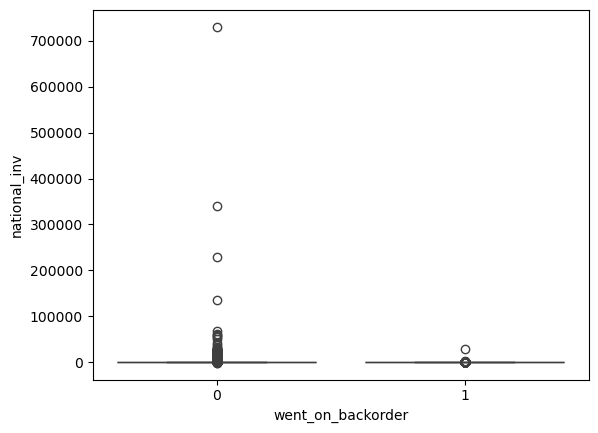

In [35]:


sns.boxplot(data=df, x="went_on_backorder", y="national_inv")
plt.show()

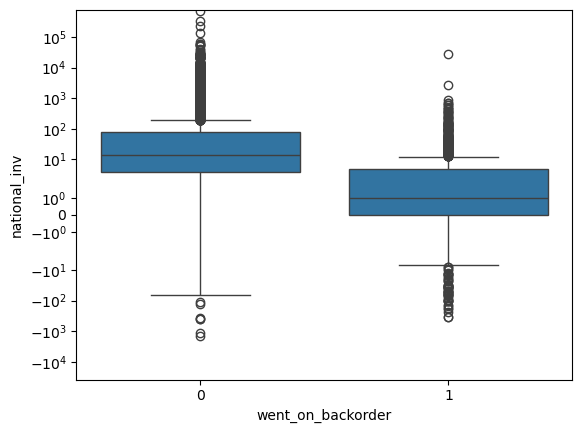

In [36]:
sns.boxplot(data=df, x="went_on_backorder", y="national_inv")
plt.yscale("symlog")
plt.show()

In [37]:
df.groupby("went_on_backorder")[
    ["sales_1_month", "sales_3_month", "sales_6_month", "sales_9_month"]
].mean()

,sales_1_month,sales_3_month,sales_6_month,sales_9_month
went_on_backorder,,,,
0,58.773045,173.842740,350.798436,533.165674
1,25.521787,73.587424,133.329288,188.477110


In [38]:
df.groupby("went_on_backorder")[
    ["forecast_3_month", "forecast_6_month", "forecast_9_month"]
].mean()

,forecast_3_month,forecast_6_month,forecast_9_month
went_on_backorder,,,
0,171.062174,334.439762,492.614892
1,251.926089,390.332046,506.839493


In [39]:
df.groupby("went_on_backorder")["in_transit_qty"].mean()

went_on_backorder
0    54.429635
1     4.861555
Name: in_transit_qty, dtype: float64

In [40]:
df.groupby("went_on_backorder")["min_bank"].mean()

went_on_backorder
0    48.142368
1    23.762272
Name: min_bank, dtype: float64

In [41]:
df.groupby("went_on_backorder")["pieces_past_due"].mean()

went_on_backorder
0    1.423529
1    2.732488
Name: pieces_past_due, dtype: float64

In [42]:
df.groupby("went_on_backorder")[
    ["perf_6_month_avg", "perf_12_month_avg"]
].mean()

,perf_6_month_avg,perf_12_month_avg
went_on_backorder,,
0,0.785489,0.779227
1,0.709002,0.706242


In [43]:
df.groupby("went_on_backorder")[
    ["potential_issue", "deck_risk", "oe_constraint", "ppap_risk",
     "stop_auto_buy", "rev_stop"]
].mean()

,potential_issue,deck_risk,oe_constraint,ppap_risk,stop_auto_buy,rev_stop
went_on_backorder,,,,,,
0,0.000298,0.226880,0.000298,0.117573,0.967759,0.000596
1,0.006619,0.172642,0.000000,0.149476,0.956977,0.000000


In [44]:
df.groupby("went_on_backorder")["local_bo_qty"].mean()

went_on_backorder
0    0.569918
1    2.639823
Name: local_bo_qty, dtype: float64

In [45]:
df.groupby("went_on_backorder")[
    ["national_inv", "in_transit_qty", "min_bank",
     "forecast_3_month", "forecast_6_month", "forecast_9_month",
     "sales_1_month", "sales_3_month", "sales_6_month", "sales_9_month",
     "pieces_past_due"]
].mean()

,national_inv,in_transit_qty,min_bank,forecast_3_month,forecast_6_month,forecast_9_month,sales_1_month,sales_3_month,sales_6_month,sales_9_month,pieces_past_due
went_on_backorder,,,,,,,,,,,
0,406.971854,54.429635,48.142368,171.062174,334.439762,492.614892,58.773045,173.842740,350.798436,533.165674,1.423529
1,26.875345,4.861555,23.762272,251.926089,390.332046,506.839493,25.521787,73.587424,133.329288,188.477110,2.732488


### 10. Feature Engineering

In [46]:
df["inventory_demand_gap"] = (
    df["national_inv"] - df["forecast_3_month"]
)

df[["national_inv", "forecast_3_month", "inventory_demand_gap"]].head()

,national_inv,forecast_3_month,inventory_demand_gap
0,1,1,0
1,11,0,11
2,99,0,99
3,18,0,18
4,1,0,1


In [47]:
df["total_available_supply"] = (
    df["national_inv"] + df["in_transit_qty"]
)

df[[
    "national_inv",
    "in_transit_qty",
    "total_available_supply"
]].head()

,national_inv,in_transit_qty,total_available_supply
0,1,1,2
1,11,0,11
2,99,0,99
3,18,0,18
4,1,0,1


In [48]:
df["supply_demand_ratio"] = np.where(
    df["forecast_3_month"] > 0,
    df["total_available_supply"] / df["forecast_3_month"],
    np.nan
)

df[
    [
        "total_available_supply",
        "forecast_3_month",
        "supply_demand_ratio"
    ]
].head()

,total_available_supply,forecast_3_month,supply_demand_ratio
0,2,1,2.0
1,11,0,NaN
2,99,0,NaN
3,18,0,NaN
4,1,0,NaN


In [49]:
df["sales_trend_1m_vs_3m"] = np.where(
    df["sales_3_month"] > 0,
    (df["sales_1_month"] * 3) / df["sales_3_month"],
    np.nan
)

df["sales_trend_3m_vs_6m"] = np.where(
    df["sales_6_month"] > 0,
    (df["sales_3_month"] * 2) / df["sales_6_month"],
    np.nan
)

In [50]:
df[
    [
        "sales_1_month",
        "sales_3_month",
        "sales_trend_1m_vs_3m",
        "sales_6_month",
        "sales_trend_3m_vs_6m"
    ]
].head()

,sales_1_month,sales_3_month,sales_trend_1m_vs_3m,sales_6_month,sales_trend_3m_vs_6m
0,0,1,0.0,1,2.0
1,1,2,1.5,5,0.8
2,0,0,NaN,0,NaN
3,1,1,3.0,1,2.0
4,1,1,3.0,1,2.0


In [51]:
df.groupby("went_on_backorder")[
    [
        "inventory_demand_gap",
        "total_available_supply",
        "supply_demand_ratio",
        "sales_trend_1m_vs_3m"
    ]
].mean()

,inventory_demand_gap,total_available_supply,supply_demand_ratio,sales_trend_1m_vs_3m
went_on_backorder,,,,
0,235.909680,461.401489,2.797235,0.932085
1,-225.050745,31.736900,0.270219,1.121436


In [52]:
df.groupby("went_on_backorder")[
    [
        "sales_trend_1m_vs_3m",
        "sales_trend_3m_vs_6m"
    ]
].mean()

,sales_trend_1m_vs_3m,sales_trend_3m_vs_6m
went_on_backorder,,
0,0.932085,1.008017
1,1.121436,1.212293


In [53]:
print("forecast_3_month = 0:", (df["forecast_3_month"] == 0).sum())
print("forecast_3_month <= 3:", (df["forecast_3_month"] <= 3).sum())

forecast_3_month = 0: 9709
forecast_3_month <= 3: 10533


In [54]:
df.groupby("went_on_backorder")[
    [
        "supply_demand_ratio",
        "inventory_demand_gap",
        "total_available_supply",
        "sales_trend_1m_vs_3m",
        "sales_trend_3m_vs_6m"
    ]
].mean()

,supply_demand_ratio,inventory_demand_gap,total_available_supply,sales_trend_1m_vs_3m,sales_trend_3m_vs_6m
went_on_backorder,,,,,
0,2.797235,235.909680,461.401489,0.932085,1.008017
1,0.270219,-225.050745,31.736900,1.121436,1.212293


In [55]:
df["inventory_forecast_ratio"] = np.where(
    df["forecast_3_month"] > 0,
    df["national_inv"] / df["forecast_3_month"],
    np.nan
)

In [56]:
df.groupby("went_on_backorder")[
    "supply_demand_ratio"
].mean()

went_on_backorder
0    2.797235
1    0.270219
Name: supply_demand_ratio, dtype: float64

In [57]:
df["forecast_3m_zero"] = (df["forecast_3_month"] == 0).astype(int)
df["sales_3m_zero"] = (df["sales_3_month"] == 0).astype(int)
df["sales_6m_zero"] = (df["sales_6_month"] == 0).astype(int)

print(df[[
    "forecast_3m_zero",
    "sales_3m_zero",
    "sales_6m_zero"
]].sum())

forecast_3m_zero    9709
sales_3m_zero       6428
sales_6m_zero       5502
dtype: int64


### 11. Preparing the Target and Predictors

The target (went_on_backorder) is separated from the predictors. sku (an identifier), Validation (a pre-made split flag in the Kaggle file) and local_bo_qty are excluded from the predictors.

In [58]:
# Target variable
y = df["went_on_backorder"]

# Remove columns that should not be used for prediction
X = df.drop(columns=[
    "went_on_backorder",
    "sku",
    "Validation",
    "local_bo_qty"
])

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (15243, 32)
y shape: (15243,)


### Why `local_bo_qty` Was Excluded

`local_bo_qty` represents the quantity of a product already associated with a local backorder condition. Since the objective of this project is to predict whether a product will go on backorder, using this variable could provide information that is too closely related to the target outcome.

To make the model more suitable as an early-warning system, `local_bo_qty` was excluded from the predictor variables. The model instead relies on inventory, demand, supply, lead time, supplier performance, and operational risk information available before the backorder outcome.


### 12. Training, Validation, and Test Split

The data is split 80/20 into a development set and a final test set. The development set is split 80/20 again into training and validation sets. All splits are stratified so each keeps the same backorder rate. Training data is used to fit models, validation data to compare models and choose the threshold, and the test set is used once at the end.

In [59]:
from sklearn.model_selection import train_test_split

# Step 1: Create development set and final test set
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Step 2: Split development set into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.20,
    random_state=42,
    stratify=y_dev
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

X_train: (9755, 32)
X_val: (2439, 32)
X_test: (3049, 32)
y_train: (9755,)
y_val: (2439,)
y_test: (3049,)


In [60]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))

Training target distribution:
went_on_backorder
0    0.881087
1    0.118913
Name: proportion, dtype: float64

Validation target distribution:
went_on_backorder
0    0.881099
1    0.118901
Name: proportion, dtype: float64


In [61]:
print("Training:")
print("forecast_3_month = 0:", (X_train["forecast_3_month"] == 0).sum())
print("sales_3_month = 0:", (X_train["sales_3_month"] == 0).sum())
print("sales_6_month = 0:", (X_train["sales_6_month"] == 0).sum())

print("\nValidation:")
print("forecast_3_month = 0:", (X_val["forecast_3_month"] == 0).sum())
print("sales_3_month = 0:", (X_val["sales_3_month"] == 0).sum())
print("sales_6_month = 0:", (X_val["sales_6_month"] == 0).sum())

Training:
forecast_3_month = 0: 6214
sales_3_month = 0: 4113
sales_6_month = 0: 3532

Validation:
forecast_3_month = 0: 1543
sales_3_month = 0: 1032
sales_6_month = 0: 867


In [62]:
print(X_train.dtypes.value_counts())

print("\nObject columns:")
print(X_train.select_dtypes(include="object").columns.tolist())

int64      25
float64     7
Name: count, dtype: int64

Object columns:
[]


### 13. Missing-Value Handling and Preprocessing

In [63]:
missing_summary = X_train.isna().sum()

missing_summary = missing_summary[missing_summary > 0].sort_values(ascending=False)

print(missing_summary)

supply_demand_ratio         6214
inventory_forecast_ratio    6214
sales_trend_1m_vs_3m        4113
sales_trend_3m_vs_6m        3532
perf_6_month_avg             710
perf_12_month_avg            662
lead_time                    546
dtype: int64


In [64]:
for col in [
    "lead_time",
    "perf_6_month_avg",
    "perf_12_month_avg",
    "supply_demand_ratio",
    "sales_trend_1m_vs_3m",
    "sales_trend_3m_vs_6m"
]:
    print("\n", col)
    print(
        df.groupby(df[col].isna())["went_on_backorder"]
        .agg(["count", "mean"])
    )


 lead_time
           count      mean
lead_time                 
False      14411  0.122060
True         832  0.064904

 perf_6_month_avg
                  count      mean
perf_6_month_avg                 
False             14163  0.123138
True               1080  0.063889

 perf_12_month_avg
                   count      mean
perf_12_month_avg                 
False              14234  0.123015
True                1009  0.061447

 supply_demand_ratio
                     count      mean
supply_demand_ratio                 
False                 5534  0.277557
True                  9709  0.028530

 sales_trend_1m_vs_3m
                      count      mean
sales_trend_1m_vs_3m                 
False                  8815  0.169030
True                   6428  0.050249

 sales_trend_3m_vs_6m
                      count      mean
sales_trend_3m_vs_6m                 
False                  9741  0.158813
True                   5502  0.048346


In [65]:
impute_cols = [
    "lead_time",
    "perf_6_month_avg",
    "perf_12_month_avg",
    "supply_demand_ratio",
    "sales_trend_1m_vs_3m",
    "sales_trend_3m_vs_6m"
]

print(X_train[impute_cols].median())

lead_time               8.000000
perf_6_month_avg        0.840000
perf_12_month_avg       0.820000
supply_demand_ratio     0.678819
sales_trend_1m_vs_3m    0.888889
sales_trend_3m_vs_6m    1.000000
dtype: float64


In [66]:
impute_cols = [
    "lead_time",
    "perf_6_month_avg",
    "perf_12_month_avg",
    "inventory_forecast_ratio",
    "supply_demand_ratio",
    "sales_trend_1m_vs_3m",
    "sales_trend_3m_vs_6m"
]

train_medians = X_train[impute_cols].median()

X_train[impute_cols] = X_train[impute_cols].fillna(train_medians)
X_val[impute_cols] = X_val[impute_cols].fillna(train_medians)
X_test[impute_cols] = X_test[impute_cols].fillna(train_medians)

print("Missing values in X_train:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

print("\nMissing values in X_val:")
print(X_val.isna().sum()[X_val.isna().sum() > 0])

print("\nMissing values in X_test:")
print(X_test.isna().sum()[X_test.isna().sum() > 0])

Missing values in X_train:
Series([], dtype: int64)

Missing values in X_val:
Series([], dtype: int64)

Missing values in X_test:
Series([], dtype: int64)


In [67]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)


X_train shape: (9755, 32)
X_val shape: (2439, 32)


In [68]:
print("X_train columns:", len(X_train.columns))
print("X_test columns:", len(X_test.columns))

print("\nColumns in X_test but not X_train:")
print(X_test.columns.difference(X_train.columns))

print("\nColumns in X_train but not X_test:")
print(X_train.columns.difference(X_test.columns))

X_train columns: 32
X_test columns: 32

Columns in X_test but not X_train:
Index([], dtype='object')

Columns in X_train but not X_test:
Index([], dtype='object')


### 14. Feature Scaling

Scaling is used for Logistic Regression only, because it is sensitive to feature scale. The scaler is fit on the training data only. Tree-based models do not need scaling.

In [69]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_val_scaled shape:", X_val_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (9755, 32)
X_val_scaled shape: (2439, 32)
X_test_scaled shape: (3049, 32)


### 15. Model Training and Comparison

Logistic Regression, Decision Tree and Random Forest are trained and compared on the validation set. All use `class_weight="balanced"` to handle the class imbalance.

In [70]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

log_reg = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=1000
)

log_reg.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [71]:
y_val_pred = log_reg.predict(X_val_scaled)
y_val_prob = log_reg.predict_proba(X_val_scaled)[:, 1]

print(classification_report(y_val, y_val_pred))
print("ROC-AUC:", roc_auc_score(y_val, y_val_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

              precision    recall  f1-score   support

           0       0.97      0.78      0.87      2149
           1       0.34      0.83      0.48       290

    accuracy                           0.79      2439
   macro avg       0.66      0.81      0.67      2439
weighted avg       0.90      0.79      0.82      2439

ROC-AUC: 0.8845854527366377

Confusion Matrix:
[[1679  470]
 [  48  242]]


In [72]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

dt_model.fit(X_train, y_train)

y_val_pred = dt_model.predict(X_val)
y_val_prob = dt_model.predict_proba(X_val)[:, 1]

print(classification_report(y_val, y_val_pred))

print("ROC-AUC:", roc_auc_score(y_val, y_val_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

              precision    recall  f1-score   support

           0       0.95      0.95      0.95      2149
           1       0.62      0.60      0.61       290

    accuracy                           0.91      2439
   macro avg       0.78      0.78      0.78      2439
weighted avg       0.91      0.91      0.91      2439

ROC-AUC: 0.7781807095521573

Confusion Matrix:
[[2041  108]
 [ 115  175]]


In [73]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [74]:
y_val_pred_rf = rf_model.predict(X_val)
y_val_prob_rf = rf_model.predict_proba(X_val)[:, 1]

print(classification_report(y_val, y_val_pred_rf))

print("ROC-AUC:", roc_auc_score(y_val, y_val_prob_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))

              precision    recall  f1-score   support

           0       0.95      0.97      0.96      2149
           1       0.76      0.60      0.67       290

    accuracy                           0.93      2439
   macro avg       0.85      0.79      0.82      2439
weighted avg       0.93      0.93      0.93      2439

ROC-AUC: 0.945546445018533

Confusion Matrix:
[[2093   56]
 [ 115  175]]


In [75]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Compare models using validation data
models = {
    "Logistic Regression": (log_reg, X_val_scaled),
    "Decision Tree": (dt_model, X_val),
    "Random Forest": (rf_model, X_val)
}

results = []

for name, (model, X_eval) in models.items():

    # Predict backorder probabilities
    y_prob = model.predict_proba(X_eval)[:, 1]

    # Convert probabilities into predictions using threshold 0.5
    y_pred = (y_prob >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Backorder Precision": precision_score(y_val, y_pred),
        "Backorder Recall": recall_score(y_val, y_pred),
        "Backorder F1": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

model_comparison = pd.DataFrame(results)

model_comparison.round(3).style.hide(axis="index")

Model,Accuracy,Backorder Precision,Backorder Recall,Backorder F1,ROC-AUC
Logistic Regression,0.788000,0.340000,0.834000,0.483000,0.885000
Decision Tree,0.909000,0.618000,0.603000,0.611000,0.778000
Random Forest,0.930000,0.758000,0.603000,0.672000,0.946000


### 16. Threshold Tuning and Hyperparameter Search

In [76]:

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

rf_tuning = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [200, 300, 400],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    estimator=rf_tuning,
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(grid_search.best_score_)


Fitting 3 folds for each of 36 candidates, totalling 108 fits
Best Parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 400}

Best Cross-Validation F1 Score:
0.6903550635334402


In [77]:

from sklearn.metrics import precision_score, recall_score, f1_score

y_val_prob_tuned = best_rf.predict_proba(X_val)[:, 1]

thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

for threshold in thresholds:
    y_pred_threshold = (
        y_val_prob_tuned >= threshold
    ).astype(int)

    precision = precision_score(
        y_val, y_pred_threshold, zero_division=0
    )
    recall = recall_score(
        y_val, y_pred_threshold, zero_division=0
    )
    f1 = f1_score(
        y_val, y_pred_threshold, zero_division=0
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1: {f1:.3f}"
    )


Threshold: 0.20 | Precision: 0.522 | Recall: 0.876 | F1: 0.654
Threshold: 0.25 | Precision: 0.561 | Recall: 0.841 | F1: 0.673
Threshold: 0.30 | Precision: 0.599 | Recall: 0.821 | F1: 0.693
Threshold: 0.35 | Precision: 0.625 | Recall: 0.793 | F1: 0.699
Threshold: 0.40 | Precision: 0.651 | Recall: 0.772 | F1: 0.707
Threshold: 0.45 | Precision: 0.672 | Recall: 0.721 | F1: 0.696
Threshold: 0.50 | Precision: 0.743 | Recall: 0.690 | F1: 0.716


### Threshold Selection

The classification threshold was evaluated on the validation set using precision, recall, and F1-score. Among the tested thresholds, **0.50 achieved the highest F1-score of 0.716**, with a precision of 0.743 and recall of 0.690.

For an early-warning system, recall is important because failing to identify a product that may go on backorder can affect inventory planning. A lower threshold can increase recall but may also generate more false-positive alerts. Therefore, the final threshold should reflect the business priority between identifying as many potential backorders as possible and avoiding unnecessary alerts.

The threshold should be selected using the validation set and then kept fixed for the final evaluation on the test set.


### 17. Validation and Final Test Evaluation

The tuned model is evaluated on the validation set at the selected threshold of 0.50, and then once on the held-out test set.

In [78]:
from sklearn.metrics import classification_report, confusion_matrix

final_threshold = 0.50

y_val_final = (
    y_val_prob_tuned >= final_threshold
).astype(int)

print("Classification Report:")
print(classification_report(y_val, y_val_final, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_final))

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.97      0.96      2149
           1       0.74      0.69      0.72       290

    accuracy                           0.93      2439
   macro avg       0.85      0.83      0.84      2439
weighted avg       0.93      0.93      0.93      2439

Confusion Matrix:
[[2080   69]
 [  90  200]]


In [79]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

y_test_prob_final = best_rf.predict_proba(X_test)[:, 1]

y_test_final = (
    y_test_prob_final >= final_threshold
).astype(int)

print("Final Test Classification Report:")
print(classification_report(
    y_test, y_test_final, zero_division=0
))

print("Final Test ROC-AUC:")
print(roc_auc_score(y_test, y_test_prob_final))

print("\nFinal Test Confusion Matrix:")
print(confusion_matrix(y_test, y_test_final))

Final Test Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.97      0.96      2686
           1       0.72      0.67      0.69       363

    accuracy                           0.93      3049
   macro avg       0.84      0.82      0.83      3049
weighted avg       0.93      0.93      0.93      3049

Final Test ROC-AUC:
0.94998964121688

Final Test Confusion Matrix:
[[2592   94]
 [ 121  242]]


### Final Test Evaluation

The tuned Random Forest model was evaluated on the held-out test set using the classification threshold of 0.50, which was selected using the validation set. The model achieved an accuracy of approximately 93% and a ROC-AUC score of 0.950.

For the backorder class, the model achieved a precision of 72%, recall of 67%, and F1-score of 0.69. It correctly identified 242 of the 363 actual backorders, while 121 backorders were missed and 94 false-positive predictions were generated.

The test results are broadly consistent with the validation results, suggesting that the model generalizes reasonably well to unseen data. However, some actual backorders remain undetected, so the model's predictions should support inventory planning rather than replace business judgment.

### 18. Feature Importance
Feature importance from the Random Forest shows which variables the model relies on most. It shows what the model uses for prediction, not what causes backorders.

In [80]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15))

                     Feature  Importance
23      inventory_demand_gap    0.121895
25       supply_demand_ratio    0.120461
28  inventory_forecast_ratio    0.109631
0               national_inv    0.072730
24    total_available_supply    0.071254
5           forecast_9_month    0.053659
4           forecast_6_month    0.048287
3           forecast_3_month    0.047375
29          forecast_3m_zero    0.034646
14         perf_12_month_avg    0.033598
13          perf_6_month_avg    0.032581
9              sales_9_month    0.032380
8              sales_6_month    0.031585
7              sales_3_month    0.026603
27      sales_trend_3m_vs_6m    0.025866


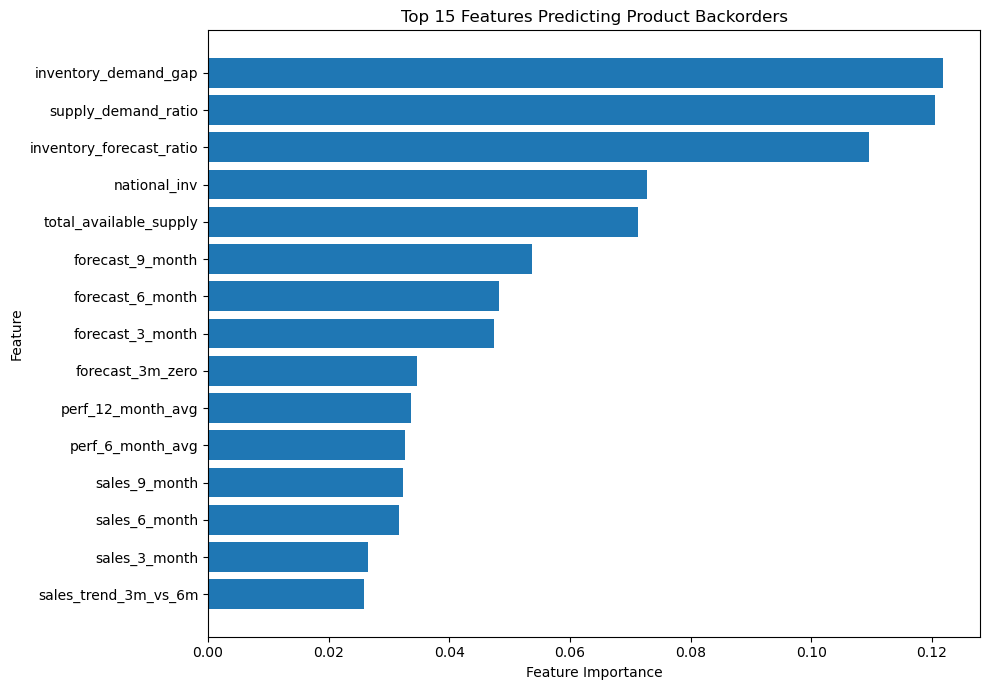

In [81]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features Predicting Product Backorders")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Feature Importance Analysis

The most important features were `inventory_demand_gap`, `supply_demand_ratio`, and `inventory_forecast_ratio`. This indicates that inventory availability relative to demand plays an important role in predicting product backorders. Feature importance reflects predictive contribution, not causation.

### 19. Model Comparison and Prediction Analysis

The models are compared on the validation set using a threshold of 0.50. The final model's predicted backorder count at the same threshold is then compared with the actual count on the test set.

In [82]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

models = {
    "Logistic Regression": (log_reg, X_val_scaled),
    "Decision Tree": (dt_model, X_val),
    "Random Forest": (rf_model, X_val),
    "Tuned Random Forest": (best_rf, X_val)
}

results = []

for name, (model, X_eval) in models.items():
    y_prob = model.predict_proba(X_eval)[:, 1]
    y_pred = (y_prob >= 0.50).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Backorder Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Backorder Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "Backorder F1": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

model_comparison = pd.DataFrame(results)

model_comparison.round(3).style.hide(axis="index")


Model,Accuracy,Backorder Precision,Backorder Recall,Backorder F1,ROC-AUC
Logistic Regression,0.788000,0.340000,0.834000,0.483000,0.885000
Decision Tree,0.909000,0.618000,0.603000,0.611000,0.778000
Random Forest,0.930000,0.758000,0.603000,0.672000,0.946000
Tuned Random Forest,0.935000,0.743000,0.690000,0.716000,0.949000


In [83]:

actual_counts = pd.Series(y_test).value_counts().reindex(
    [0, 1], fill_value=0
)

predicted_counts = pd.Series(y_test_final).value_counts().reindex(
    [0, 1], fill_value=0
)

comparison_counts = pd.DataFrame({
    "Actual": actual_counts.values,
    "Predicted": predicted_counts.values
}, index=["No Backorder", "Backorder"])

comparison_counts


,Actual,Predicted
No Backorder,2686,2713
Backorder,363,336


### 20. Precision–Recall Analysis

The Precision–Recall curve for the final model on the test set shows the trade-off between precision and recall across thresholds. PR-AUC summarises it in one number and is more informative than ROC-AUC for imbalanced data.

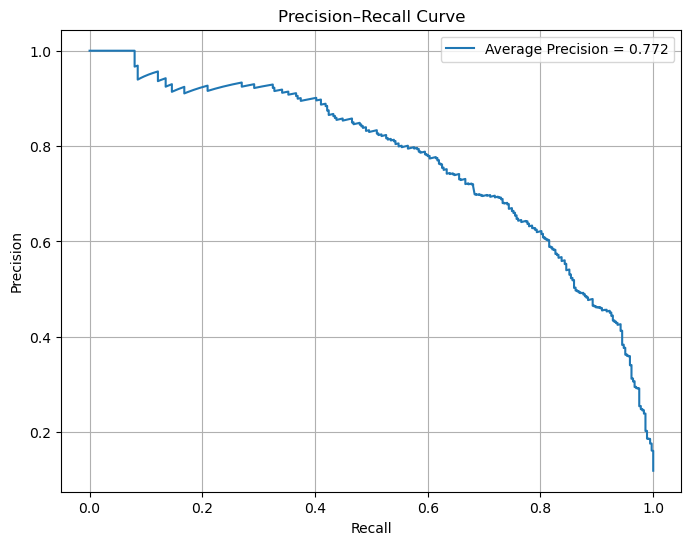

In [84]:
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score
import matplotlib.pyplot as plt

y_test_proba = best_rf.predict_proba(X_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_test_proba
)

plt.figure(figsize=(8, 6))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.grid()
pr_auc = average_precision_score(y_test, y_test_proba)
plt.legend([f"Average Precision = {pr_auc:.3f}"])
plt.show()

### 21.Saving the Model for Deployment

The final trained model and the information required for deployment, including training medians, the prediction threshold, and feature names, are saved. New data must undergo the same feature engineering and median imputation used during training before predictions are generated. Products with a predicted backorder probability of 0.50 or higher are flagged as backorder risks.

In [85]:
import joblib

# Save the final trained model
joblib.dump(best_rf, "backorder_random_forest.pkl")

# Save preprocessing and deployment information
deployment_info = {
    "impute_cols": impute_cols,
    "train_medians": train_medians.to_dict(),
    "final_threshold": final_threshold,
    "feature_names": X_train.columns.tolist()
}

joblib.dump(deployment_info, "backorder_preprocessing.pkl")

print("Model and preprocessing information saved successfully.")

Model and preprocessing information saved successfully.


In [86]:

# Verify that the saved files can be loaded
loaded_model = joblib.load("backorder_random_forest.pkl")
loaded_info = joblib.load("backorder_preprocessing.pkl")

print("Model loaded:", type(loaded_model).__name__)
print("Saved threshold:", loaded_info["final_threshold"])
print("Number of features:", len(loaded_info["feature_names"]))
print("Number of imputation columns:", len(loaded_info["impute_cols"]))


Model loaded: RandomForestClassifier
Saved threshold: 0.5
Number of features: 32
Number of imputation columns: 7


In [87]:
print("Imputation columns:")
print(loaded_info["impute_cols"])

print("\nSaved training medians:")
print(loaded_info["train_medians"])

Imputation columns:
['lead_time', 'perf_6_month_avg', 'perf_12_month_avg', 'inventory_forecast_ratio', 'supply_demand_ratio', 'sales_trend_1m_vs_3m', 'sales_trend_3m_vs_6m']

Saved training medians:
{'lead_time': 8.0, 'perf_6_month_avg': 0.84, 'perf_12_month_avg': 0.82, 'inventory_forecast_ratio': 0.5454545454545454, 'supply_demand_ratio': 0.6788194444444444, 'sales_trend_1m_vs_3m': 0.8888888888888888, 'sales_trend_3m_vs_6m': 1.0}


In [88]:
from sklearn.metrics import average_precision_score

pr_auc = average_precision_score(y_test, y_test_proba)

print("Test PR-AUC:", pr_auc)

Test PR-AUC: 0.7717337427239953


### Business Interpretation of Feature Importance

The model relies heavily on inventory-demand relationships, particularly `inventory_demand_gap`, `supply_demand_ratio`, and `inventory_forecast_ratio`. Current inventory, available supply, demand forecasts, and historical sales also contribute to backorder-risk predictions. These features indicate predictive relationships, not direct causation.

### Business Recommendations

1. **Prioritize high-risk products:** Review products with high predicted backorder probabilities.
2. **Monitor inventory and demand:** Identify products where available supply may be insufficient for expected demand.
3. **Review incoming supply:** Monitor in-transit quantities and supplier performance.
4. **Support business decisions:** Use predictions as an early-warning tool alongside human review.

### Limitations

- **False positives:** 94 products were incorrectly flagged as backorder risks.
- **Missed backorders:** 121 of 363 actual backorders were not identified.
- **Historical data:** Future performance may change with demand and supply conditions.
- **Prediction is not causation:** Feature importance does not establish cause-and-effect relationships.

### Conclusion

This project developed a machine learning model to identify products at risk of going on backorder using inventory, demand, sales, and supply-related features. After comparing multiple models and tuning a Random Forest classifier, the final model achieved **93% accuracy, 0.950 ROC-AUC, and 0.772 Average Precision (AP)** on the test set. At a threshold of **0.50**, it identified 242 of 363 actual backorders, with 94 false-positive alerts and 121 missed backorders.

The model can support inventory monitoring and supply-chain planning by helping teams prioritize high-risk products. Future improvements could include testing newer data and monitoring model performance over time.

### Final Model Validation for Streamlit Deployment

In [100]:
print("Test data shape:", X_test.shape)
print("Sample input:", X_test.head(1).to_dict(orient="records"))
print("Sample actual outcome:", y_test.iloc[0])

Test data shape: (3049, 32)
Sample input: [{'national_inv': 0, 'lead_time': 8.0, 'in_transit_qty': 0, 'forecast_3_month': 8, 'forecast_6_month': 8, 'forecast_9_month': 8, 'sales_1_month': 0, 'sales_3_month': 0, 'sales_6_month': 0, 'sales_9_month': 0, 'min_bank': 4, 'potential_issue': 0, 'pieces_past_due': 0, 'perf_6_month_avg': 0.79, 'perf_12_month_avg': 0.71, 'deck_risk': 1, 'oe_constraint': 0, 'ppap_risk': 1, 'stop_auto_buy': 1, 'rev_stop': 0, 'perf_6_missing': 0, 'perf_12_missing': 0, 'lead_time_missing': 0, 'inventory_demand_gap': -8, 'total_available_supply': 0, 'supply_demand_ratio': 0.0, 'sales_trend_1m_vs_3m': 0.8888888888888888, 'sales_trend_3m_vs_6m': 1.0, 'inventory_forecast_ratio': 0.0, 'forecast_3m_zero': 0, 'sales_3m_zero': 1, 'sales_6m_zero': 1}]
Sample actual outcome: 1


In [101]:
import joblib

model = joblib.load("backorder_random_forest.pkl")
info = joblib.load("backorder_preprocessing.pkl")

test_row = X_test.iloc[[1]]
actual_result = y_test.iloc[1]

probability = model.predict_proba(test_row)[0, 1]
prediction = int(probability >= info["final_threshold"])

print("Notebook probability:", round(probability * 100, 1), "%")
print("Notebook prediction:", prediction)
print("Actual result:", actual_result)

Notebook probability: 89.2 %
Notebook prediction: 1
Actual result: 1


In [102]:
# Find the first test row whose actual outcome is 0
row_index = y_test[y_test == 0].index[0]

test_row = X_test.loc[[row_index]]
actual_result = y_test.loc[row_index]

print("Actual outcome:", actual_result)
print("Input values:")
print(test_row.to_dict(orient="records")[0])

Actual outcome: 0
Input values:
{'national_inv': 0, 'lead_time': 9.0, 'in_transit_qty': 0, 'forecast_3_month': 5, 'forecast_6_month': 6, 'forecast_9_month': 6, 'sales_1_month': 0, 'sales_3_month': 0, 'sales_6_month': 0, 'sales_9_month': 0, 'min_bank': 0, 'potential_issue': 0, 'pieces_past_due': 0, 'perf_6_month_avg': 0.7, 'perf_12_month_avg': 0.66, 'deck_risk': 0, 'oe_constraint': 0, 'ppap_risk': 1, 'stop_auto_buy': 1, 'rev_stop': 0, 'perf_6_missing': 0, 'perf_12_missing': 0, 'lead_time_missing': 0, 'inventory_demand_gap': -5, 'total_available_supply': 0, 'supply_demand_ratio': 0.0, 'sales_trend_1m_vs_3m': 0.8888888888888888, 'sales_trend_3m_vs_6m': 1.0, 'inventory_forecast_ratio': 0.0, 'forecast_3m_zero': 0, 'sales_3m_zero': 1, 'sales_6m_zero': 1}


In [103]:
probability = model.predict_proba(test_row)[0, 1]
prediction = int(probability >= info["final_threshold"])

print("Notebook probability:", round(probability * 100, 1), "%")
print("Notebook prediction:", prediction)
print("Actual result:", actual_result)

Notebook probability: 17.7 %
Notebook prediction: 0
Actual result: 0
